# Adversarial Attacks and Defenses on MNIST

This notebook attacks a small CNN with **FGSM** and **PGD**, then tests three defenses: input quantization, adversarial training and model ensembles.

The main question is not just *whether* a defense helps, but *how it is evaluated*. A defense tested against attacks crafted on a different model (a transfer attack) can look much stronger than it is. Here every defense is evaluated against attacks crafted on the defended model itself (white-box), and compared with the weaker transfer evaluation.

**Runtime:** about 10 to 15 minutes on a Colab T4 GPU (**Runtime → Change runtime type → T4 GPU**). Then use **Runtime → Run all**.

In [1]:
import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as T

def set_seed(seed):
    torch.manual_seed(seed)
    np.random.seed(seed)

set_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)
print(f"Device: {device} | PyTorch {torch.__version__}")

Device: cuda | PyTorch 2.14.1+cu130


## 1. Data and model

In [2]:
transform = T.ToTensor()  # pixels in [0, 1]
trainset = torchvision.datasets.MNIST(root="./data", train=True, download=True, transform=transform)
testset = torchvision.datasets.MNIST(root="./data", train=False, download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=64, shuffle=True)
testloader = torch.utils.data.DataLoader(testset, batch_size=256, shuffle=False)
print(f"Train: {len(trainset)} | Test: {len(testset)}")


class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)
        self.fc1 = nn.Linear(64 * 7 * 7, 128)
        self.fc2 = nn.Linear(128, 10)
        self.dropout = nn.Dropout(0.25)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = x.view(-1, 64 * 7 * 7)
        x = self.dropout(F.relu(self.fc1(x)))
        return self.fc2(x)

100%|██████████| 9.91M/9.91M [00:00<00:00, 11.5MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 310kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 2.94MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 7.08MB/s]

Train: 60000 | Test: 10000


## 2. Attacks

In [3]:
def fgsm(model, x, y, eps):
    """Fast Gradient Sign Method: one step of size eps in the direction of the loss gradient's sign."""
    was_training = model.training
    model.eval()
    x = x.clone().detach().requires_grad_(True)
    loss = F.cross_entropy(model(x), y)
    grad, = torch.autograd.grad(loss, x)  # gradient w.r.t. the input only
    model.train(was_training)
    return (x + eps * grad.sign()).clamp(0, 1).detach()


def pgd(model, x, y, eps, alpha=0.01, steps=40):
    """Projected Gradient Descent: repeated small FGSM steps, projected back into the eps-ball."""
    was_training = model.training
    model.eval()
    x0 = x.clone().detach()
    x_adv = (x0 + torch.empty_like(x0).uniform_(-eps, eps)).clamp(0, 1).detach()  # random start
    for _ in range(steps):
        x_adv.requires_grad_(True)
        loss = F.cross_entropy(model(x_adv), y)
        grad, = torch.autograd.grad(loss, x_adv)
        x_adv = x_adv.detach() + alpha * grad.sign()
        x_adv = torch.min(torch.max(x_adv, x0 - eps), x0 + eps).clamp(0, 1).detach()
    model.train(was_training)
    return x_adv


def accuracy(model, loader):
    model.eval()
    correct = total = 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            correct += (model(x).argmax(1) == y).sum().item()
            total += y.size(0)
    return 100 * correct / total


def adv_accuracy(target, loader, attack, source=None, **attack_kwargs):
    """Accuracy of `target` on adversarial examples crafted against `source`.
    source=None means white-box (crafted against the target itself)."""
    source = target if source is None else source
    target.eval()
    correct = total = 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        x_adv = attack(source, x, y, **attack_kwargs)
        with torch.no_grad():
            correct += (target(x_adv).argmax(1) == y).sum().item()
        total += y.size(0)
    return 100 * correct / total

## 3. Train the standard model

In [4]:
def train(model, epochs=3, adversarial=None, eps=0.1, desc="model"):
    """Train a model. adversarial: None (standard), "fgsm" or "pgd".
    Adversarial training uses a 50/50 mix of clean and adversarial loss."""
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    start = time.time()
    for epoch in range(epochs):
        model.train()
        running = 0.0
        for x, y in trainloader:
            x, y = x.to(device), y.to(device)
            if adversarial == "fgsm":
                x_adv = fgsm(model, x, y, eps)
            elif adversarial == "pgd":
                x_adv = pgd(model, x, y, eps, alpha=eps / 4, steps=7)
            model.train()
            if adversarial:
                loss = 0.5 * F.cross_entropy(model(x), y) + 0.5 * F.cross_entropy(model(x_adv), y)
            else:
                loss = F.cross_entropy(model(x), y)
            opt.zero_grad()
            loss.backward()
            opt.step()
            running += loss.item()
        print(f"[{desc}] epoch {epoch + 1}/{epochs} loss {running / len(trainloader):.4f}")
    print(f"[{desc}] trained in {time.time() - start:.0f}s | clean test accuracy {accuracy(model, testloader):.2f}%")
    return model


set_seed(0)
standard = train(SimpleCNN().to(device), epochs=3, desc="standard")

[standard] epoch 1/3 loss 0.2044
[standard] epoch 2/3 loss 0.0624
[standard] epoch 3/3 loss 0.0473
[standard] trained in 33s | clean test accuracy 99.05%


## 4. Attack strength: FGSM vs PGD

eps=0.00 | FGSM  99.05% | PGD  99.05%
eps=0.05 | FGSM  96.34% | PGD  95.24%
eps=0.10 | FGSM  89.13% | PGD  74.95%
eps=0.15 | FGSM  72.66% | PGD  22.67%
eps=0.20 | FGSM  46.90% | PGD   1.32%
eps=0.25 | FGSM  21.47% | PGD   0.00%
eps=0.30 | FGSM   8.50% | PGD   0.00%


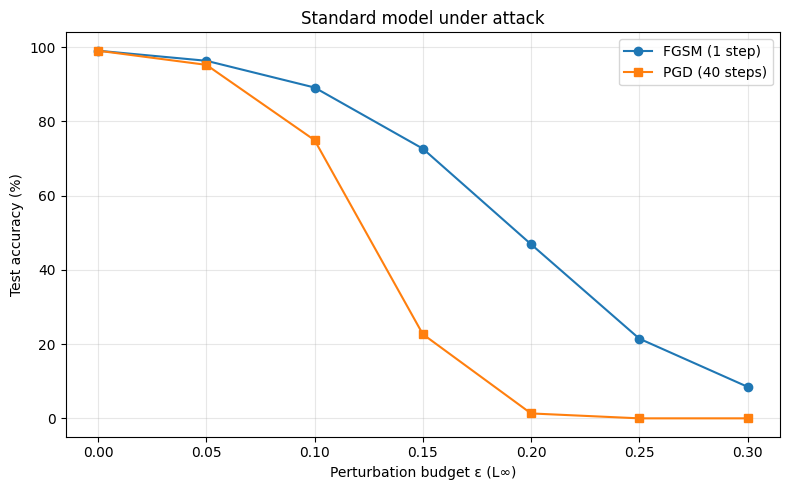

In [5]:
epsilons = [0.0, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3]
sweep = []
for eps in epsilons:
    f = adv_accuracy(standard, testloader, fgsm, eps=eps)
    p = adv_accuracy(standard, testloader, pgd, eps=eps)
    sweep.append({"epsilon": eps, "FGSM": f, "PGD": p})
    print(f"eps={eps:.2f} | FGSM {f:6.2f}% | PGD {p:6.2f}%")
sweep = pd.DataFrame(sweep)
sweep.to_csv("results/attack_strength.csv", index=False)

plt.figure(figsize=(8, 5))
plt.plot(sweep.epsilon, sweep.FGSM, "o-", label="FGSM (1 step)")
plt.plot(sweep.epsilon, sweep.PGD, "s-", label="PGD (40 steps)")
plt.xlabel("Perturbation budget ε (L∞)")
plt.ylabel("Test accuracy (%)")
plt.title("Standard model under attack")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("figures/attack_strength.png", dpi=150)
plt.show()

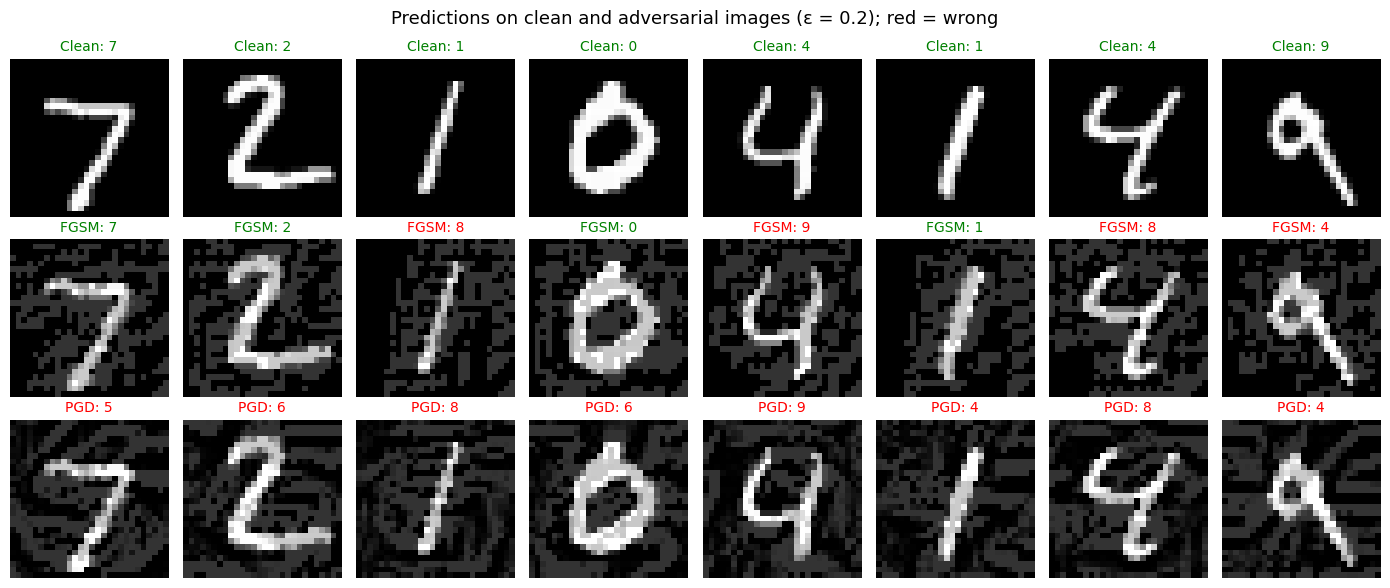

In [6]:
# Visualize clean vs adversarial examples (eps = 0.2)
x, y = next(iter(testloader))
x, y = x[:8].to(device), y[:8].to(device)
x_fgsm, x_pgd = fgsm(standard, x, y, 0.2), pgd(standard, x, y, 0.2)
with torch.no_grad():
    preds = [standard(v).argmax(1) for v in (x, x_fgsm, x_pgd)]

fig, axes = plt.subplots(3, 8, figsize=(14, 6))
for row, (imgs, pred, name) in enumerate(zip((x, x_fgsm, x_pgd), preds, ("Clean", "FGSM", "PGD"))):
    for i in range(8):
        ax = axes[row, i]
        ax.imshow(imgs[i].cpu().squeeze(), cmap="gray")
        ax.set_title(f"{name}: {pred[i].item()}", color="green" if pred[i] == y[i] else "red", fontsize=10)
        ax.axis("off")
plt.suptitle("Predictions on clean and adversarial images (ε = 0.2); red = wrong", fontsize=13)
plt.tight_layout()
plt.savefig("figures/adversarial_examples.png", dpi=150)
plt.show()

## 5. Defense 1: input quantization

Reducing pixel precision can wash out small perturbations. Quantization is not differentiable, so there are three ways to attack it:

- **Unaware attacker:** crafts the attack on the undefended model, then the defense is applied.
- **Naive white-box:** attacks the quantized model directly. The rounding step has zero gradient, so the attack gets no signal. This is *gradient masking*, and it makes the defense look stronger than it is.
- **Adaptive (BPDA):** treats quantization as the identity on the backward pass (Athalye et al., 2018), which gives the attacker useful gradients again.

In [7]:
def quantize(x, bits):
    levels = 2 ** bits - 1
    return torch.round(x * levels) / levels


class Quantized(nn.Module):
    def __init__(self, model, bits, bpda=False):
        super().__init__()
        self.model, self.bits, self.bpda = model, bits, bpda

    def forward(self, x):
        q = quantize(x, self.bits)
        if self.bpda:
            q = x + (q - x).detach()  # forward: quantized, backward: identity
        return self.model(q)


rows = []
for bits in (4, 1):
    defended = Quantized(standard, bits)
    adaptive = Quantized(standard, bits, bpda=True)
    for eps in (0.1, 0.2):
        rows.append({
            "bits": bits, "epsilon": eps,
            "no defense": adv_accuracy(standard, testloader, pgd, eps=eps),
            "unaware attacker": adv_accuracy(defended, testloader, pgd, source=standard, eps=eps),
            "naive white-box": adv_accuracy(defended, testloader, pgd, eps=eps),
            "adaptive (BPDA)": adv_accuracy(defended, testloader, pgd, source=adaptive, eps=eps),
        })
quant_results = pd.DataFrame(rows)
quant_results.to_csv("results/quantization.csv", index=False)
print("Clean accuracy with 4-bit / 1-bit input:",
      f"{accuracy(Quantized(standard, 4), testloader):.2f}% / {accuracy(Quantized(standard, 1), testloader):.2f}%")
quant_results.round(2)

Clean accuracy with 4-bit / 1-bit input: 99.06% / 98.85%


,bits,epsilon,no defense,unaware attacker,naive white-box,adaptive (BPDA)
0,4,0.1,74.90,57.60,99.01,53.96
1,4,0.2,1.43,1.60,98.97,3.00
2,1,0.1,75.09,97.06,98.78,96.48
3,1,0.2,1.38,93.73,98.71,92.85


## 6. Defenses 2 and 3: adversarial training and ensembles

- **FGSM adversarial training:** each batch mixes clean and FGSM examples (ε = 0.1).
- **PGD adversarial training:** the same, but with a 7-step PGD attack (Madry et al., 2018).
- **Ensemble:** three standard models trained from different random seeds, combined by averaging their logits.

Each model is tested two ways: the **original evaluation** (FGSM examples crafted on the *standard* model and transferred, which is how the course notebook measured it) and **white-box** attacks crafted on the model itself.

In [8]:
set_seed(1)
fgsm_at = train(SimpleCNN().to(device), epochs=3, adversarial="fgsm", eps=0.1, desc="FGSM-AT")
set_seed(2)
pgd_at = train(SimpleCNN().to(device), epochs=3, adversarial="pgd", eps=0.1, desc="PGD-AT")

members = []
for seed in (10, 11, 12):
    set_seed(seed)
    members.append(train(SimpleCNN().to(device), epochs=3, desc=f"ensemble member {seed}"))


class Ensemble(nn.Module):
    def __init__(self, models):
        super().__init__()
        self.models = nn.ModuleList(models)

    def forward(self, x):
        return torch.stack([m(x) for m in self.models]).mean(0)


ensemble = Ensemble(members).to(device)

[FGSM-AT] epoch 1/3 loss 0.3054
[FGSM-AT] epoch 2/3 loss 0.1227
[FGSM-AT] epoch 3/3 loss 0.0954
[FGSM-AT] trained in 39s | clean test accuracy 99.06%
[PGD-AT] epoch 1/3 loss 0.3358
[PGD-AT] epoch 2/3 loss 0.1391
[PGD-AT] epoch 3/3 loss 0.1109
[PGD-AT] trained in 63s | clean test accuracy 99.10%
[ensemble member 10] epoch 1/3 loss 0.2190
[ensemble member 10] epoch 2/3 loss 0.0694
[ensemble member 10] epoch 3/3 loss 0.0512
[ensemble member 10] trained in 30s | clean test accuracy 99.01%
[ensemble member 11] epoch 1/3 loss 0.2207
[ensemble member 11] epoch 2/3 loss 0.0692
[ensemble member 11] epoch 3/3 loss 0.0522
[ensemble member 11] trained in 30s | clean test accuracy 98.98%
[ensemble member 12] epoch 1/3 loss 0.2101
[ensemble member 12] epoch 2/3 loss 0.0626
[ensemble member 12] epoch 3/3 loss 0.0466
[ensemble member 12] trained in 30s | clean test accuracy 99.03%


In [9]:
models = {"Standard": standard, "FGSM-AT": fgsm_at, "PGD-AT": pgd_at, "Ensemble (3)": ensemble}
rows = []
for name, m in models.items():
    row = {"model": name, "clean": accuracy(m, testloader)}
    row["FGSM 0.15, transfer (original eval)"] = adv_accuracy(m, testloader, fgsm, source=standard, eps=0.15)
    for eps in (0.1, 0.2):
        row[f"FGSM {eps}, white-box"] = adv_accuracy(m, testloader, fgsm, eps=eps)
        row[f"PGD {eps}, white-box"] = adv_accuracy(m, testloader, pgd, eps=eps)
    rows.append(row)
    print(f"Evaluated {name}")

robustness = pd.DataFrame(rows).set_index("model")
robustness.to_csv("results/robustness.csv")
robustness.round(2)

Evaluated Standard
Evaluated FGSM-AT
Evaluated PGD-AT
Evaluated Ensemble (3)


,clean,"FGSM 0.15, transfer (original eval)","FGSM 0.1, white-box","PGD 0.1, white-box","FGSM 0.2, white-box","PGD 0.2, white-box"
model,,,,,,
Standard,99.05,72.66,89.13,74.92,46.90,1.51
FGSM-AT,99.06,94.94,96.44,87.84,88.27,17.60
PGD-AT,99.10,95.49,95.91,94.89,87.28,66.93
Ensemble (3),99.19,90.11,91.53,86.42,54.00,8.25


In [ ]:
cols = ["clean", "FGSM 0.15, transfer (original eval)", "PGD 0.1, white-box", "PGD 0.2, white-box"]
ax = robustness[cols].plot(kind="bar", figsize=(11, 5.5), width=0.8)
ax.set_ylabel("Test accuracy (%)")
ax.set_xlabel("")
ax.set_title("Defenses under transfer vs white-box evaluation")
ax.set_ylim(0, 105)
ax.grid(axis="y", alpha=0.3)
plt.xticks(rotation=0)
plt.legend(loc="lower left", fontsize=9)
plt.tight_layout()
plt.savefig("figures/defense_comparison.png", dpi=150)
plt.show()

## 7. Summary

In [11]:
print("Attack strength (standard model):")
print(sweep.round(2).to_string(index=False))
print("\nInput quantization (PGD):")
print(quant_results.round(2).to_string(index=False))
print("\nRobustness of each model:")
print(robustness.round(2).to_string())

Attack strength (standard model):
 epsilon  FGSM   PGD
    0.00 99.05 99.05
    0.05 96.34 95.24
    0.10 89.13 74.95
    0.15 72.66 22.67
    0.20 46.90  1.32
    0.25 21.47  0.00
    0.30  8.50  0.00

Input quantization (PGD):
 bits  epsilon  no defense  unaware attacker  naive white-box  adaptive (BPDA)
    4      0.1       74.90             57.60            99.01            53.96
    4      0.2        1.43              1.60            98.97             3.00
    1      0.1       75.09             97.06            98.78            96.48
    1      0.2        1.38             93.73            98.71            92.85

Robustness of each model:
              clean  FGSM 0.15, transfer (original eval)  FGSM 0.1, white-box  PGD 0.1, white-box  FGSM 0.2, white-box  PGD 0.2, white-box
model                                                                                                                                     
Standard      99.05                                72.66               